In [1]:
from joblib import Parallel, delayed

from matplotlib.figure import Figure
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
import qutrit_analytical as an3
import experimental as ex


def scan_analytical_qutrit(alpha_goal, gap_func, gap_min=0.001, gap_max=1000):
    energies = an3.scan_gaps(alpha_goal, gap_func, iters=400, gap_min=gap_min, gap_max=gap_max)
    if len(energies) == 0:
        return alpha_goal, np.nan, np.nan, np.nan, np.nan
    _, _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps


alpha_space = np.linspace(0.501, 0.999, 50)
#alpha_space = np.linspace(0.501, 0.7, 50)

def scan_parallel_qutrit(func):
    return Parallel(n_jobs=-2)(
        delayed(scan_analytical_qutrit)(alpha, func) for alpha in tqdm(alpha_space, leave=True)
    )

best_gaps11 = scan_parallel_qutrit(an3.case1_first_swap)

best_gaps12 = scan_parallel_qutrit(an3.case1_second_swap)

best_gaps21 = scan_parallel_qutrit(an3.case2_first_swap)

best_gaps22 = scan_parallel_qutrit(an3.case2_second_swap)

100%|██████████| 50/50 [00:00<00:00, 59.12it/s]


In [2]:
import ququart_analytical as an4

def scan_parallel_ququart(func):
    return Parallel(n_jobs=-2)(
        delayed(an4.scan_analytical)(alpha, func, iters=100) for alpha in tqdm(alpha_space, leave=True)
    )

best_gaps_quart_full = scan_parallel_ququart(an4.full_swap)

100%|██████████| 50/50 [00:08<00:00,  6.07it/s]


In [3]:
def scan_experimental_qutrit(alpha_goal):
    energies = ex.scan_gaps(3, alpha_goal, iters=100, gap_min=0.001, gap_max=100)
    _, _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps


best_gaps_exp_trit = Parallel(n_jobs=-2)(
    delayed(scan_experimental_qutrit)(alpha) for alpha in tqdm(alpha_space, leave=True)
)

100%|██████████| 50/50 [00:05<00:00,  9.60it/s]


In [4]:
def scan_experimental_quart(alpha_goal):
    energies = ex.scan_gaps(4, alpha_goal, iters=30, gap_min=0.001, gap_max=100)
    _, _, _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps


best_gaps_exp_quart = Parallel(n_jobs=-2)(
    delayed(scan_experimental_quart)(alpha) for alpha in tqdm(alpha_space, leave=True)
)

100%|██████████| 50/50 [00:18<00:00,  2.74it/s]


In [5]:
def scan_experimental_bit(alpha_goal):
    energies = ex.scan_gaps(2, alpha_goal, iters=600, gap_min=0.001, gap_max=100)
    _, e_values, _ = zip(*energies)
    min_gaps = energies[np.argmin(e_values)]
    return alpha_goal, *min_gaps


best_gaps_exp_bit = Parallel(n_jobs=-2)(
    delayed(scan_experimental_bit)(alpha) for alpha in tqdm(alpha_space, leave=True)
)

100%|██████████| 50/50 [00:00<00:00, 430.93it/s]


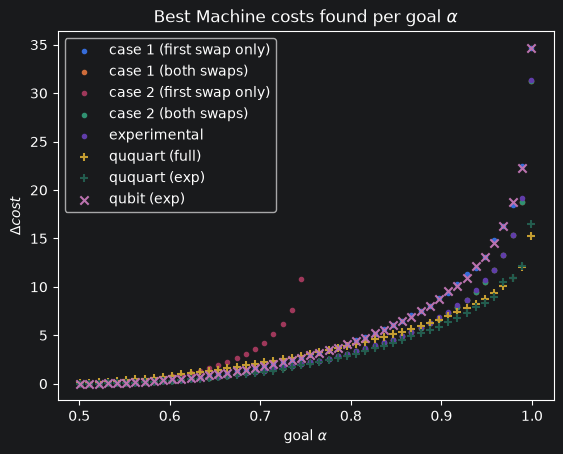

In [6]:
alphas4, _, _, _, energies4, _ = zip(*best_gaps_quart_full)
alphas_exp4, _, _, _, energies_exp4, _ = zip(*best_gaps_exp_quart)

alphas11, _, _, energies11, _ = zip(*best_gaps11)
alphas12, _, _, energies12, _ = zip(*best_gaps12)
alphas21, _, _, energies21, _ = zip(*best_gaps21)
alphas22, _, _, energies22, _ = zip(*best_gaps22)
alphas_exp3, _, _, energies_exp3, _ = zip(*best_gaps_exp_trit)

alphas_exp2, _, energies_exp2, _ = zip(*best_gaps_exp_bit)

ax = plt.gca()
#ax.set_yscale('log')

ax.scatter(alphas11, energies11, marker='.', label=r"case 1 (first swap only)")
ax.scatter(alphas12, energies12, marker='.', label=r"case 1 (both swaps)")
ax.scatter(alphas21, energies21, marker='.', label=r"case 2 (first swap only)")
ax.scatter(alphas22, energies22, marker='.', label=r"case 2 (both swaps)")
ax.scatter(alphas_exp3, energies_exp3, marker='.', label=r"experimental")

ax.scatter(alphas4, energies4, marker='+', label=r"ququart (full)")
ax.scatter(alphas_exp4, energies_exp4, marker='+', label=r"ququart (exp)")

ax.scatter(alphas_exp2, energies_exp2, marker='x', label=r"qubit (exp)")

ax.set_ylabel(r"$\Delta cost$")
ax.set_xlabel(r"goal $\alpha$")
plt.title(r'Best Machine costs found per goal $\alpha$')
ax.legend()

plt.show()